# Harmonic oscillator

In the potential $V = \omega^2 x^2/2$ a Gaussian with width $\sigma = 1/\sqrt{\omega}$ is a
*coherent state*: it oscillates like a classical particle without changing its shape,

$$\langle x\rangle(t) = x_0\cos\omega t + \frac{p_0}{\omega}\sin\omega t.$$

This notebook also shows two ways to get the energy spectrum $E_n = \omega(n + 1/2)$ from time propagation:
imaginary time evolution and the Fourier transform of the autocorrelation function.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import HTML

import so_schroedinger as so

plt.rcParams["figure.figsize"] = (8, 4)
plt.rcParams["animation.embed_limit"] = 50  # MB
plt.rcParams["figure.dpi"] = 72

In [2]:
omega = 1.0
pot = so.HarmOscPot(omega)
psi0 = so.CoherentState(x0=4.0, omega=omega, p0=0.0)
grid = so.Grid1d((-15.0, 15.0), 2**9, pot, psi0)
prop = so.SplitOperator()

anim = so.animate1d(grid, prop, dt=0.01, nFrames=80, stepsPerFrame=8, scalePot=0.02)
HTML(anim.to_jshtml())

## Coherent state versus classical trajectory

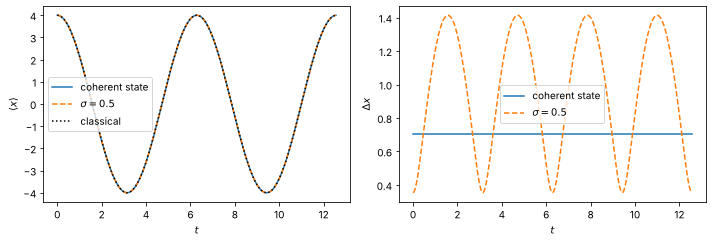

In [3]:
def run(psi0, tEnd=4*np.pi, dt=0.01):
    grid = so.Grid1d((-15.0, 15.0), 2**9, pot, psi0)
    t, x, w = [grid.t], [grid.expectationX()], [grid.widthX()]
    def record(g):
        t.append(g.t); x.append(g.expectationX()); w.append(g.widthX())
    prop.propagate(grid, dt, int(tEnd/dt), callback=record, every=5)
    return np.array(t), np.array(x), np.array(w)

t, x, w = run(so.CoherentState(4.0, omega, 0.0))
t2, x2, w2 = run(so.Gaussian1d(4.0, 0.5, 0.0))  # too narrow: not a coherent state

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(t, x, label="coherent state")
ax1.plot(t2, x2, "--", label=r"$\sigma = 0.5$")
ax1.plot(t, 4*np.cos(omega*t), "k:", label="classical")
ax1.set(xlabel="$t$", ylabel=r"$\langle x\rangle$")
ax1.legend()
ax2.plot(t, w, label="coherent state")
ax2.plot(t2, w2, "--", label=r"$\sigma = 0.5$")
ax2.set(xlabel="$t$", ylabel=r"$\Delta x$")
ax2.legend()
plt.tight_layout()

The center of every packet follows the classical trajectory (Ehrenfest's theorem is exact for
quadratic potentials). Only the coherent state keeps its width; the narrower packet "breathes" at frequency $2\omega$.

## Ground state from imaginary time evolution

Substituting $t = -i\tau$ turns $e^{-iHt}$ into $e^{-H\tau}$, which damps every eigenstate as
$e^{-E_n\tau}$. After renormalization, only the ground state survives. The norm loss per step gives its energy.

E_0 = 0.49999809856898086


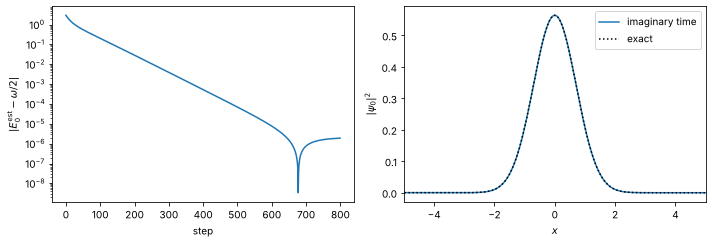

In [4]:
grid = so.Grid1d((-15.0, 15.0), 2**9, pot, so.Gaussian1d(2.0, 2.0, 1.0))
prop_imag = so.SplitOperator(renormalizeEveryNSteps=1)
energies = []
prop_imag.propagate(grid, -0.01j, 800, callback=lambda g: energies.append(prop_imag.groundStateEnergy))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.semilogy(np.abs(np.array(energies) - omega/2))
ax1.set(xlabel="step", ylabel=r"$|E_0^\mathrm{est} - \omega/2|$")
ax2.plot(grid.xVals, grid.density, label="imaginary time")
ax2.plot(grid.xVals, np.exp(-omega*grid.xVals**2)*np.sqrt(omega/np.pi), "k:", label="exact")
ax2.set(xlim=(-5, 5), xlabel="$x$", ylabel=r"$|\psi_0|^2$")
ax2.legend()
plt.tight_layout()
print("E_0 =", energies[-1])

## Spectrum from the autocorrelation function

Expanding $\psi_0 = \sum_n c_n \varphi_n$ in eigenstates gives the autocorrelation

$$C(t) = \langle\psi_0|\psi(t)\rangle = \sum_n |c_n|^2 e^{-iE_n t},$$

so the Fourier transform of $C(t)$ has peaks at the eigenenergies, weighted by $|c_n|^2$
(Feit, Fleck and Steiger, J. Comput. Phys. 47, 412 (1982)). A displaced coherent state contains a
Poisson distribution of oscillator states. A window function suppresses the artifacts of the finite time interval.

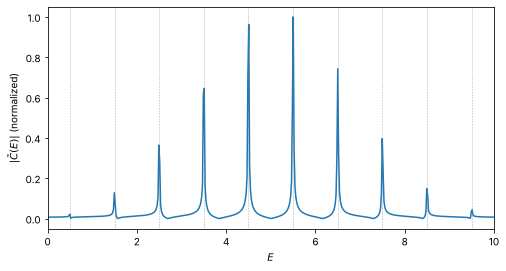

In [5]:
psi0 = so.Gaussian1d(x0=3.0, sigma=0.8, p0=0.0)
grid = so.Grid1d((-15.0, 15.0), 2**9, pot, psi0)
psiInit = grid.psi.copy()
dt, nSteps = 0.02, 2**14
C = np.empty(nSteps, dtype=complex)
for i in range(nSteps):
    C[i] = np.sum(np.conj(psiInit)*grid.psi)*grid.dx
    prop.step(grid, dt)

window = np.hanning(2*nSteps)[nSteps:]  # decays from 1 at t = 0 to 0 at t_max
E = 2*np.pi*np.fft.fftshift(np.fft.fftfreq(nSteps, dt))
spectrum = np.abs(np.fft.fftshift(np.fft.ifft(C*window)))

plt.plot(E, spectrum/spectrum.max())
for n in range(12):
    plt.axvline(omega*(n + 0.5), c="gray", lw=0.6, ls=":")
plt.xlim(0, 10)
plt.xlabel("$E$")
plt.ylabel(r"$|\tilde C(E)|$ (normalized)");

The dotted lines mark $E_n = \omega(n + 1/2)$.

With the energies known, the eigenstates follow from a windowed Fourier transform of $\psi(x, t)$
itself at $E = E_n$. This is what `so.analyzers.EigenfunctionBuilder` does.

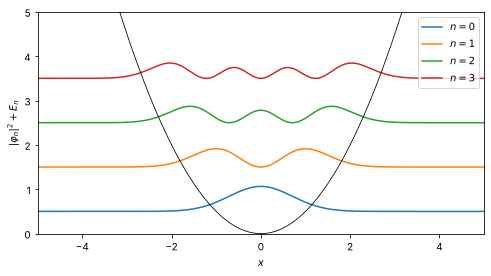

In [6]:
psi0 = so.Gaussian1d(x0=1.5, sigma=1.0, p0=0.5)
grid = so.Grid1d((-15.0, 15.0), 2**9, pot, psi0)
builder = so.analyzers.EigenfunctionBuilder(grid.xVals, grid.psi, grid.V)
builder.addData(grid.psi.copy(), grid.V, grid.t)
for i in range(2000):
    prop.propagate(grid, 0.02, 5)
    builder.addData(grid.psi.copy(), grid.V, grid.t)

for n in range(4):
    phi = builder.computeEigenfunction(omega*(n + 0.5))
    phi = phi/np.sqrt(np.sum(np.abs(phi)**2)*grid.dx)
    plt.plot(grid.xVals, np.abs(phi)**2 + omega*(n + 0.5), label=f"$n = {n}$")
plt.plot(grid.xVals, np.real(pot.V(grid.xVals, 0)), "k", lw=0.8)
plt.xlim(-5, 5)
plt.ylim(0, 5)
plt.xlabel("$x$")
plt.ylabel(r"$|\varphi_n|^2 + E_n$")
plt.legend();